# eQTL benchmark 7 — continuous and stratified gene specificity

Same nine poster models, original eQTL labels and cached scores.

- **Main inference:** all covered, common-support genes with GM12878 ≥20 processed promoter-CPM. Model-score association with eQTL status is tested across continuous specificity, adjusting for GM expression and distance.
- **Specificity:** lower mean CAGE across the 637 other biosamples = higher relative specificity; no GM/others ratio is required.
- **Main display:** split others-mean at the median among covered GM-active protein-coding background genes. Below = higher specificity; at/above = lower. No middle genes are discarded; ties stay together, and benchmark group sizes need not be equal.
- **Secondary:** retain the previous bottom-50% / top-10% extreme comparison and matching; retain ratio labels in exports.
- **Focused comparisons:** Borzoi full FT, LoRA and scratch each versus pretrained Borzoi. Scratch is a training-regime comparison, not fine-tuning.
- **Readout:** measured matching-strand CAGE summed over merged −300/+100-bp annotated promoters; normalize per biosample over covered protein-coding genes. Processed promoter-CPM is not raw-library CPM.
- The activity gate is an analysis choice; fixed 10/20/50/100 sensitivity counts are reported. Thresholds do not use benchmark labels or scores.
- These analyses are exploratory after prior inspection of thresholds and results. They do not establish causal effects or new held-out prediction performance.
- Extraction and prediction caches are reused. Only derived annotations, statistical results and plots are regenerated.


## 1. Poster models, scores and cohort

Nine arms; absolute log2 ref/alt mean ratio over a central 2,048-bp prediction crop. Retain zero effects. Common support intersects the poster's per-arm scorable masks. Original pair-row IDs are preserved.


In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
from eqtl_benchmark7_pipeline import CACHE, validate_expression_cache
import eqtl_benchmark7_analysis as an

scores, scorable, strict = an.score_pairs()
common = scorable.all(axis=1)
print(f'Original rows: {an.N_PAIRS}; common support: {common.sum()}; strict support: {strict.all(axis=1).sum()}')
assert common.sum() == 1023, 'Poster common support changed: investigate before stratification.'
assert np.array_equal(common, strict.all(axis=1)), 'Nonfinite/one-sided-zero cases change the cohort.'
assert np.isfinite(scores).all()
display(pd.DataFrame({'model': an.NAMES, 'scorable': scorable.sum(0),
                      'one_sided_zero_mean': (scorable & ~strict).sum(0)}))


Original rows: 1331; common support: 1023; strict support: 1023


,model,scorable,one_sided_zero_mean
0,cis-Mamba (1 cell type),1267,0
1,"cis-Mamba, no pretraining",1267,0
2,cis-Mamba (8 cell types),1267,0
3,Enformer (pretrained),1023,0
4,Borzoi (pretrained),1267,0
5,Borzoi LoRA (GM12878),1267,0
6,Borzoi full FT (GM12878),1267,0
7,Borzoi from scratch (GM12878),1267,0
8,AlphaGenome,1331,0


In [2]:
# Reproduce the poster's original distance-stratified AP before new annotations.
v = an.pair_table()
rows = []
for cohort, mask in [('all_rows', np.ones(an.N_PAIRS, bool)), ('all_common', common)]:
    for nm, lo, hi in an.DISTANCE_BINS:
        take = mask & (v.distance.to_numpy() >= lo) & (v.distance.to_numpy() < hi)
        for a, model in enumerate(an.NAMES):
            ap, _ = an.metric_values(v.label.to_numpy()[take], scores[take, a])
            rows.append(dict(cohort=cohort, distance=nm, model=model, n=int(take.sum()),
                             prevalence=float(v.label.to_numpy()[take].mean()), AP=ap))
poster = pd.DataFrame(rows)
poster.to_csv(CACHE / 'poster_reproduction.tsv', sep='\t', index=False)
display(poster.pivot(index='model', columns=['cohort', 'distance'], values='AP').round(4))


cohort                        all_rows                   all_common          \
distance                         <1 kb 1-10 kb 10-262 kb      <1 kb 1-10 kb   
model                                                                         
AlphaGenome                     0.7086  0.7603    0.5236     0.7086  0.7603   
Borzoi (pretrained)             0.6778  0.6464    0.3618     0.6778  0.6464   
Borzoi LoRA (GM12878)           0.6910  0.6655    0.3669     0.6910  0.6655   
Borzoi from scratch (GM12878)   0.6807  0.6232    0.3793     0.6807  0.6232   
Borzoi full FT (GM12878)        0.7125  0.6791    0.3611     0.7125  0.6791   
Enformer (pretrained)           0.6582  0.6536    0.3620     0.6582  0.6536   
cis-Mamba (1 cell type)         0.6068  0.5350    0.3497     0.6068  0.5350   
cis-Mamba (8 cell types)        0.6735  0.5597    0.3828     0.6735  0.5597   
cis-Mamba, no pretraining       0.5435  0.3781    0.3143     0.5435  0.3781   

cohort                                   
distance                      10-262 kb  
model                                    
AlphaGenome                      0.5326  
Borzoi (pretrained)              0.4230  
Borzoi LoRA (GM12878)            0.4274  
Borzoi from scratch (GM12878)    0.4250  
Borzoi full FT (GM12878)         0.4190  
Enformer (pretrained)            0.4082  
cis-Mamba (1 cell type)          0.4023  
cis-Mamba (8 cell types)         0.4459  
cis-Mamba, no pretraining        0.3367

## 2. Reuse the measured-expression cache

- `borzoi.zarr` BED spans are measured 196,608-bp intervals = 6,144 × 32 bp; no Enformer-style crop offset applies.
- Span starts use different bin origins. Window-to-span and bin assignments are cached; missing/partial windows are not silent genes.
- Matching-strand gene × biosample values are derived from `gene_cage_columns.npy`. Original both-strand values remain available as a sensitivity readout.
- Completed extraction caches are validated and reused, even with the runner's `all` stage. A different extraction setup requires a new `EQTL7_CACHE` directory.


In [3]:
import json
validate_expression_cache()
cfg = json.loads((CACHE / 'expression_manifest.json').read_text())
print(f"{cfg['n_cage_columns']} CAGE columns; {cfg['n_biosamples']} biosamples; GM12878 is one biosample with two strands.")
print('Span grid offsets:', cfg['distinct_span_grid_offsets'])
g = an.classify_genes()
classification = an.save_expression_annotations(g)
display(g.groupby(['is_benchmark', 'mapping_status']).size().unstack(fill_value=0))


1276 CAGE columns; 638 biosamples; GM12878 is one biosample with two strands.
Span grid offsets: 32


mapping_status,covered,partial,uncovered
is_benchmark,,,
False,19133,22,421
True,639,0,14


## 3. Relative specificity within GM12878-active genes

`specificity_group` is the median others-mean split used for display. `directional_group` preserves the extreme and inverse categories; `expression_group` preserves the previous ratio split. Only the two display groups partition all eligible genes.


In [4]:
threshold_columns = ['gm_high_cutoff_cpm', 'others_median_gm_active_background',
                     'n_specificity_reference_genes', 'n_background_genes', 'n_other_biosamples',
                     'others_low_cutoff_cpm', 'others_high_cutoff_cpm', 'strand_mode']
display(g[threshold_columns].iloc[:1].T.rename(columns={0: 'value'}))
display(g[g.is_benchmark].specificity_group.value_counts().rename('unique benchmark genes').to_frame())
display(g[g.is_benchmark & g.specificity_group.isin(an.PRESENT)]
        [['gene_id', 'specificity_group', 'gm12878_cpm', 'others_mean_cpm']].round(3))
print('Secondary extreme categories:')
display(g[g.is_benchmark].directional_group.value_counts().to_frame())


,value
gm_high_cutoff_cpm,20.0
others_median_gm_active_background,77.879613
n_specificity_reference_genes,9991
n_background_genes,19638
n_other_biosamples,637
others_low_cutoff_cpm,40.911479
others_high_cutoff_cpm,115.446828
strand_mode,sense


,unique benchmark genes
specificity_group,
gm_active_others_lower,237
gm_active_others_higher,223
gm_not_expressed,179
missing,14


,gene_id,specificity_group,gm12878_cpm,others_mean_cpm
52,ENSG00000004534,gm_active_others_higher,132.737,112.084
128,ENSG00000006282,gm_active_others_higher,79.284,77.944
250,ENSG00000010270,gm_active_others_higher,184.684,138.379
330,ENSG00000013374,gm_active_others_higher,139.070,99.057
336,ENSG00000013561,gm_active_others_higher,72.575,89.722
...,...,...,...,...
19425,ENSG00000273061,gm_active_others_lower,30.531,19.844
19542,ENSG00000275765,gm_active_others_lower,23.383,29.471
19626,ENSG00000278259,gm_active_others_higher,141.548,95.657
20013,ENSG00000286813,gm_active_others_lower,39.973,30.980


Secondary extreme categories:


,count
directional_group,
intermediate,361
low_in_both,112
gm_high_others_high,90
gm_high_others_low,76
missing,14


In [5]:
# Sensitivity only: GM activity gates 10, 20, 50, 100 CPM; recompute reference median.
# Low gate tracks the active gate at one fifth (2, 4, 10, 20 CPM);
# matching versus combined strands, and inclusion/exclusion of B-lineage comparators.
# These results do not select or change the primary thresholds.
sensitivity = an.sweep_cutoff()
display(sensitivity)


,high_cpm,low_cpm,strand_mode,lymphoid_excluded,others_low_cpm,others_high_cpm,gm_active_others_lower,gm_active_others_higher,gm_not_expressed,missing,gm_low_others_high,no_active_reference
0,10.0,2.0,sense,False,40.911479,115.446828,247,238,154,14,0,0
1,10.0,2.0,sense,True,40.918189,115.518392,249,236,154,14,0,0
2,20.0,4.0,sense,False,40.911479,115.446828,237,223,179,14,0,0
3,20.0,4.0,sense,True,40.918189,115.518392,237,223,179,14,0,0
4,50.0,10.0,sense,False,40.911479,115.446828,196,191,252,14,0,0
5,50.0,10.0,sense,True,40.918189,115.518392,195,192,252,14,0,0
6,100.0,20.0,sense,False,40.911479,115.446828,105,102,432,14,1,0
7,100.0,20.0,sense,True,40.918189,115.518392,105,102,432,14,1,0
8,10.0,2.0,combined,False,39.957971,117.773549,238,277,124,14,0,0
9,10.0,2.0,combined,True,39.916678,117.676948,239,276,124,14,0,0


## 4. Stratified benchmark

- Identical common-support rows across models within each group; retain baseline and excluded-group counts.
- AP and AUROC require both positive and negative pairs. Report undefined values as missing, not zero or chance.
- 400 bootstrap draws resample target genes, with identical draws across models. Shared variants/LD across different genes are not modeled; intervals are descriptive.
- AP − prevalence is descriptive, **not** a correction for class imbalance. Distance, gene activity and candidate composition may differ between groups.


In [6]:
pairs = an.annotate_pairs()
table, draws = an.stratified_metrics(pairs, scores, scorable, n_boot=400, by_distance=True)
summary = (table[table.distance_bin == 'all']
           [['stratum', 'n', 'positives', 'prevalence', 'n_genes', 'median_distance']]
           .drop_duplicates().set_index('stratum'))
display(summary)
for group in an.PRESENT:
    row = summary.loc[group]
    if row.positives == 0 or row.positives == row.n:
        print(f'{group}: AP/AUROC not estimable (n={int(row.n)}, positives={int(row.positives)}).')
    elif row.n_genes < 2:
        print(f'{group}: no gene-bootstrap interval with fewer than two genes.')

# Account for pairs, positive-bearing genes and distinct variants at each exclusion.
attrition_rows = []
covered = common & pairs.gene_mapping_status.eq('covered').to_numpy()
active = covered & pairs.gm12878_cpm.ge(an.GM_HIGH_CPM).to_numpy()
for label, take in [('Original', np.ones(len(pairs), bool)), ('Common support', common),
                    ('Covered CAGE', covered), ('GM12878 active', active)] + [
                    (group, an.group_mask(pairs, common, group)) for group in an.PRESENT + an.EXTREME]:
    sub = pairs[take]; pos = sub[sub.label.eq(1)]
    attrition_rows.append(dict(cohort=label, pairs=len(sub), positives=len(pos),
                               genes=sub.gene_id.nunique(), positive_genes=pos.gene_id.nunique(),
                               variants=sub[['chrom_name', 'qtl_loc']].drop_duplicates().shape[0]))
attrition = pd.DataFrame(attrition_rows)
attrition.to_csv(CACHE / 'cohort_attrition.tsv', sep='\t', index=False)
display(attrition.set_index('cohort'))
assert np.array_equal(active, an.group_mask(pairs, common, an.PRESENT[0]) | an.group_mask(pairs, common, an.PRESENT[1]))


,n,positives,prevalence,n_genes,median_distance
stratum,,,,,
gm_active_others_lower,397,83,0.209068,208,14159.0
gm_active_others_higher,368,64,0.173913,201,16348.5
gm_expressed_more_specific,461,87,0.188720,234,18628.0
gm_expressed_broad,304,60,0.197368,175,11322.5
gm_not_expressed,244,65,0.266393,153,17260.0
no_active_reference,0,0,NaN,0,NaN
all_rows,1331,232,0.174305,658,29512.0
all_common,1023,218,0.213099,575,15582.0
annotated,1009,212,0.210109,562,15561.0


,pairs,positives,genes,positive_genes,variants
cohort,,,,,
Original,1331,232,658,228,1248
Common support,1023,218,575,215,975
Covered CAGE,1009,212,562,209,963
GM12878 active,765,147,409,145,748
gm_active_others_lower,397,83,208,82,384
gm_active_others_higher,368,64,201,63,366
gm_high_others_low,178,33,71,33,169
gm_high_others_high,136,27,82,26,136


In [7]:
primary = table[(table.distance_bin == 'all') & table.stratum.isin(an.PRESENT)]
display(primary.pivot(index='model', columns='stratum', values=['AP', 'AUROC', 'AP_ci_low', 'AP_ci_high'])
        .reindex(an.NAMES).round(4))
# Keep distances and shared-variant dependencies visible for interpretation.
common_pairs = pairs[common]
display(pd.crosstab(common_pairs.specificity_group, common_pairs.distance_bin))
variant_keys = common_pairs.chrom_name + ':' + common_pairs.qtl_loc.astype(str)
shared = common_pairs.assign(variant_key=variant_keys).groupby('variant_key').gene_id.nunique()
print('Common-support variants linked to multiple target genes:', int((shared > 1).sum()))


AP                         \
stratum                       gm_active_others_higher gm_active_others_lower   
model                                                                          
cis-Mamba (1 cell type)                        0.4087                 0.5755   
cis-Mamba, no pretraining                      0.3446                 0.5731   
cis-Mamba (8 cell types)                       0.4587                 0.6270   
Enformer (pretrained)                          0.5147                 0.5788   
Borzoi (pretrained)                            0.5476                 0.6083   
Borzoi LoRA (GM12878)                          0.5139                 0.6444   
Borzoi full FT (GM12878)                       0.5406                 0.6518   
Borzoi from scratch (GM12878)                  0.4706                 0.6532   
AlphaGenome                                    0.5265                 0.6555   

                                                AUROC                         \
stratum                       gm_active_others_higher gm_active_others_lower   
model                                                                          
cis-Mamba (1 cell type)                        0.7617                 0.8117   
cis-Mamba, no pretraining                      0.7515                 0.8179   
cis-Mamba (8 cell types)                       0.7988                 0.8306   
Enformer (pretrained)                          0.8115                 0.7982   
Borzoi (pretrained)                            0.8030                 0.8241   
Borzoi LoRA (GM12878)                          0.7781                 0.8533   
Borzoi full FT (GM12878)                       0.7894                 0.8599   
Borzoi from scratch (GM12878)                  0.8070                 0.8482   
AlphaGenome                                    0.7490                 0.8483   

                                            AP_ci_low                         \
stratum                       gm_active_others_higher gm_active_others_lower   
model                                                                          
cis-Mamba (1 cell type)                        0.3032                 0.4749   
cis-Mamba, no pretraining                      0.2522                 0.4728   
cis-Mamba (8 cell types)                       0.3480                 0.5131   
Enformer (pretrained)                          0.3923                 0.4845   
Borzoi (pretrained)                            0.4296                 0.4943   
Borzoi LoRA (GM12878)                          0.4019                 0.5377   
Borzoi full FT (GM12878)                       0.4261                 0.5516   
Borzoi from scratch (GM12878)                  0.3411                 0.5595   
AlphaGenome                                    0.4007                 0.5631   

                                           AP_ci_high                         
stratum                       gm_active_others_higher gm_active_others_lower  
model                                                                         
cis-Mamba (1 cell type)                        0.5580                 0.6908  
cis-Mamba, no pretraining                      0.5062                 0.6891  
cis-Mamba (8 cell types)                       0.6228                 0.7391  
Enformer (pretrained)                          0.6339                 0.6925  
Borzoi (pretrained)                            0.6686                 0.7437  
Borzoi LoRA (GM12878)                          0.6322                 0.7501  
Borzoi full FT (GM12878)                       0.6564                 0.7632  
Borzoi from scratch (GM12878)                  0.6257                 0.7573  
AlphaGenome                                    0.7053                 0.7596

distance_bin,1-10 kb,10-262 kb,<1 kb
specificity_group,,,
gm_active_others_higher,39,217,112
gm_active_others_lower,62,217,118
gm_not_expressed,44,143,57
missing,1,9,4


Common-support variants linked to multiple target genes: 45


## Main inference: continuous specificity, without discarding middle genes

Fit a separate binomial logistic regression for each model on **all eligible pairs**:

`eQTL label ~ score + specificity + GM expression + distance + score:specificity + score:GM expression + score:distance`

- Score = standardized midrank within the shared cohort; specificity = standardized `−log2(others mean + 0.1)`; GM = standardized `log2(GM + 0.1)`; distance = standardized `log(1 + distance_bp)`.
- Positive `score:specificity` means a stronger association between higher model scores and positive eQTL labels as specificity increases, conditional on the modeled covariates. It is **not** an AP change, causal effect or out-of-sample evaluation.
- Include score interactions with GM and distance so their effects on score informativeness are not forced into specificity. This is a simple parametric adjustment, not proof all confounding is removed.
- 95% intervals use a gene-cluster sandwich covariance with a finite-sample correction; paired model contrasts retain covariance from the same genes. Shared variants/LD across different genes remain a limitation.
- Focused comparisons are differences in standardized interaction coefficients; Holm-adjusted p-values cover these three comparisons only. Per-model intervals are exploratory and not simultaneous.
- Transformations are label-independent but estimated once on this cohort. Inference is conditional on these transformations and the cached expression measurements.
- Covariance reference: [statsmodels cluster sandwich documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_cluster.html).


,term,coefficient,se,ci_low,ci_high,p_value,n,positives,n_genes,converged
model,,,,,,,,,,
cis-Mamba (1 cell type),score_x_specificity,0.1195,0.1894,-0.2518,0.4908,0.5282,765,147,409,True
"cis-Mamba, no pretraining",score_x_specificity,0.4190,0.1769,0.0723,0.7657,0.0179,765,147,409,True
cis-Mamba (8 cell types),score_x_specificity,0.3612,0.1697,0.0286,0.6937,0.0333,765,147,409,True
Enformer (pretrained),score_x_specificity,0.2841,0.1648,-0.0389,0.6070,0.0847,765,147,409,True
Borzoi (pretrained),score_x_specificity,0.1125,0.2242,-0.3269,0.5519,0.6157,765,147,409,True
Borzoi LoRA (GM12878),score_x_specificity,0.3966,0.1715,0.0604,0.7328,0.0208,765,147,409,True
Borzoi full FT (GM12878),score_x_specificity,0.5977,0.2361,0.1351,1.0604,0.0113,765,147,409,True
Borzoi from scratch (GM12878),score_x_specificity,0.3382,0.1785,-0.0117,0.6881,0.0582,765,147,409,True
AlphaGenome,score_x_specificity,0.4466,0.2153,0.0246,0.8686,0.0381,765,147,409,True


,reference,delta_interaction,se,ci_low,ci_high,p_value,p_holm_three_contrasts
model,,,,,,,
Borzoi full FT (GM12878),Borzoi (pretrained),0.4852,0.2308,0.0328,0.9376,0.0355,0.1066
Borzoi LoRA (GM12878),Borzoi (pretrained),0.2841,0.1746,-0.0581,0.6263,0.1037,0.2074
Borzoi from scratch (GM12878),Borzoi (pretrained),0.2257,0.1954,-0.1573,0.6087,0.2482,0.2482


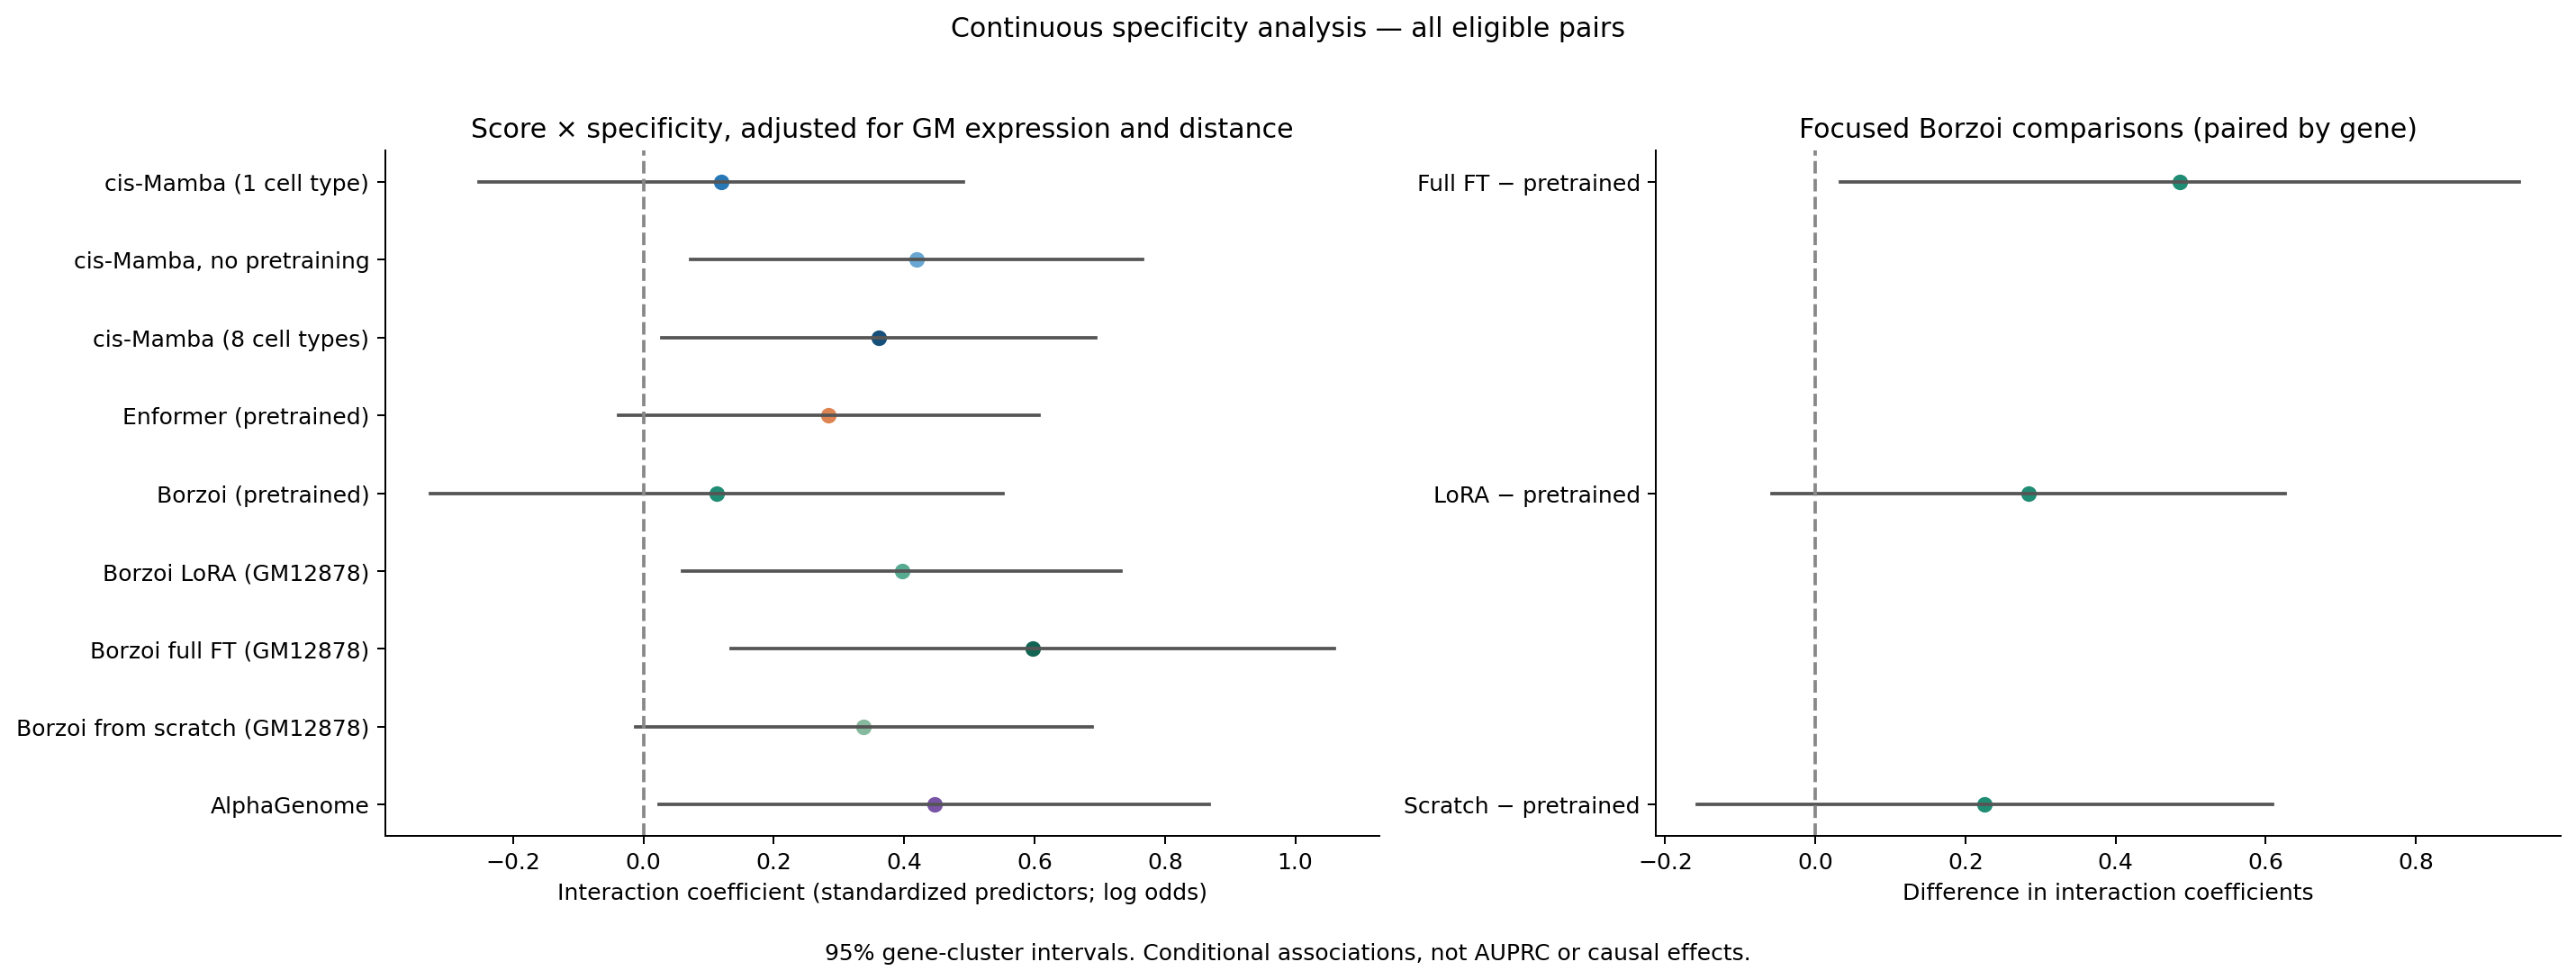

In [8]:
coefficients, continuous_comparisons = an.continuous_analysis(pairs, scores, scorable)
display(coefficients[coefficients.term.eq('score_x_specificity')].set_index('model').round(4))
display(continuous_comparisons.set_index('model').round(4))
fig = an.plot_continuous(coefficients, continuous_comparisons)
an.plt.close(fig)
display(Image(filename=str(CACHE / 'figures' / 'continuous_specificity.png')))


## 5. Focused differences in stratified AP

- Main display groups include all GM-active genes. AP gaps use identical rows and paired gene-bootstrap draws across models.
- Focus on Borzoi full FT, LoRA and scratch versus pretrained Borzoi. `higher_minus_lower` measures how the AP gap changes between specificity groups.
- These AP contrasts are descriptive and unadjusted. They do not remove prevalence, expression or distance differences.
- The earlier cis-Mamba-reference table is retained below for continuity; it is exploratory.


In [9]:
focused_ap = an.focused_ap_comparisons(draws)
display(focused_ap.round(4))
inter = an.interaction_test(draws, *an.PRESENT)
display(inter.set_index('model').round(4))


,model,reference,contrast,delta_AP,ci_low,ci_high,valid_bootstraps
0,Borzoi full FT (GM12878),Borzoi (pretrained),gm_active_others_lower,0.0434,-0.0193,0.1019,400
1,Borzoi full FT (GM12878),Borzoi (pretrained),gm_active_others_higher,-0.0070,-0.0841,0.0741,400
2,Borzoi full FT (GM12878),Borzoi (pretrained),higher_minus_lower,0.0505,-0.0522,0.1416,400
3,Borzoi LoRA (GM12878),Borzoi (pretrained),gm_active_others_lower,0.0361,-0.0253,0.0844,400
4,Borzoi LoRA (GM12878),Borzoi (pretrained),gm_active_others_higher,-0.0337,-0.0985,0.0250,400
5,Borzoi LoRA (GM12878),Borzoi (pretrained),higher_minus_lower,0.0698,-0.0283,0.1430,400
6,Borzoi from scratch (GM12878),Borzoi (pretrained),gm_active_others_lower,0.0448,-0.0452,0.1274,400
7,Borzoi from scratch (GM12878),Borzoi (pretrained),gm_active_others_higher,-0.0769,-0.1647,0.0264,400
8,Borzoi from scratch (GM12878),Borzoi (pretrained),higher_minus_lower,0.1217,-0.0077,0.2284,400


,group_a,group_b,reference,difference_of_differences,bootstrap_mean,ci_low,ci_high,valid_bootstraps,crosses_zero,CI_available
model,,,,,,,,,,
cis-Mamba (1 cell type),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),0.0000,0.0000,0.0000,0.0000,400,True,True
"cis-Mamba, no pretraining",gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),-0.0617,-0.0576,-0.1776,0.0686,400,True,True
cis-Mamba (8 cell types),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),-0.0015,0.0027,-0.1130,0.1155,400,True,True
Enformer (pretrained),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),0.1028,0.0970,-0.0469,0.2348,400,True,True
Borzoi (pretrained),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),0.1061,0.0929,-0.0412,0.2392,400,True,True
Borzoi LoRA (GM12878),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),0.0363,0.0302,-0.1050,0.1678,400,True,True
Borzoi full FT (GM12878),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),0.0556,0.0462,-0.0813,0.1922,400,True,True
Borzoi from scratch (GM12878),gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),-0.0157,-0.0203,-0.1604,0.1135,400,True,True
AlphaGenome,gm_active_others_lower,gm_active_others_higher,cis-Mamba (1 cell type),0.0378,0.0390,-0.0992,0.1949,400,True,True


### Secondary: expression-matched extreme groups

The original extreme contrast is retained with fixed 0.5-log2 matching (about 1.41-fold maximum difference) on unique genes, using seed 7. Greedy matching need not maximize the number of matches. Membership and caliper are exported under explicit filenames.

Matching reduces sample size and does not ensure pair-weighted expression, distance or prevalence balance. Report both gene- and pair-weighted expression summaries. A change in ranking is not proof that expression caused the unmatched result. This is a sensitivity check, not the main analysis.


In [10]:
matched = an.matched_sensitivity(pairs, scores, scorable, groups=an.EXTREME, caliper=0.5, seed=7)
if not matched.empty:
    display(matched.drop_duplicates('stratum')[['stratum', 'n', 'positives', 'n_genes',
                                                'prevalence', 'median_gene_gm_cpm', 'median_gm_cpm', 'caliper_log2']])
    display(matched.pivot(index='model', columns='stratum', values='AP').reindex(an.NAMES).round(4))


matched sensitivity: 18 gene pairs; median GM CPM 140.3 vs 111.8; arms favouring gm_high_others_low: 3/9


,stratum,n,positives,n_genes,prevalence,median_gene_gm_cpm,median_gm_cpm,caliper_log2
0,gm_high_others_low,74,10,18,0.135135,86.193403,140.32554,0.5
9,gm_high_others_high,27,6,18,0.222222,113.518436,111.81716,0.5


stratum,gm_high_others_high,gm_high_others_low
model,,
cis-Mamba (1 cell type),0.7695,0.4720
"cis-Mamba, no pretraining",0.5681,0.6159
cis-Mamba (8 cell types),0.8293,0.7708
Enformer (pretrained),0.6681,0.4659
Borzoi (pretrained),0.7554,0.6470
Borzoi LoRA (GM12878),0.5692,0.5718
Borzoi full FT (GM12878),0.5589,0.6823
Borzoi from scratch (GM12878),0.6665,0.6479
AlphaGenome,0.7955,0.7170


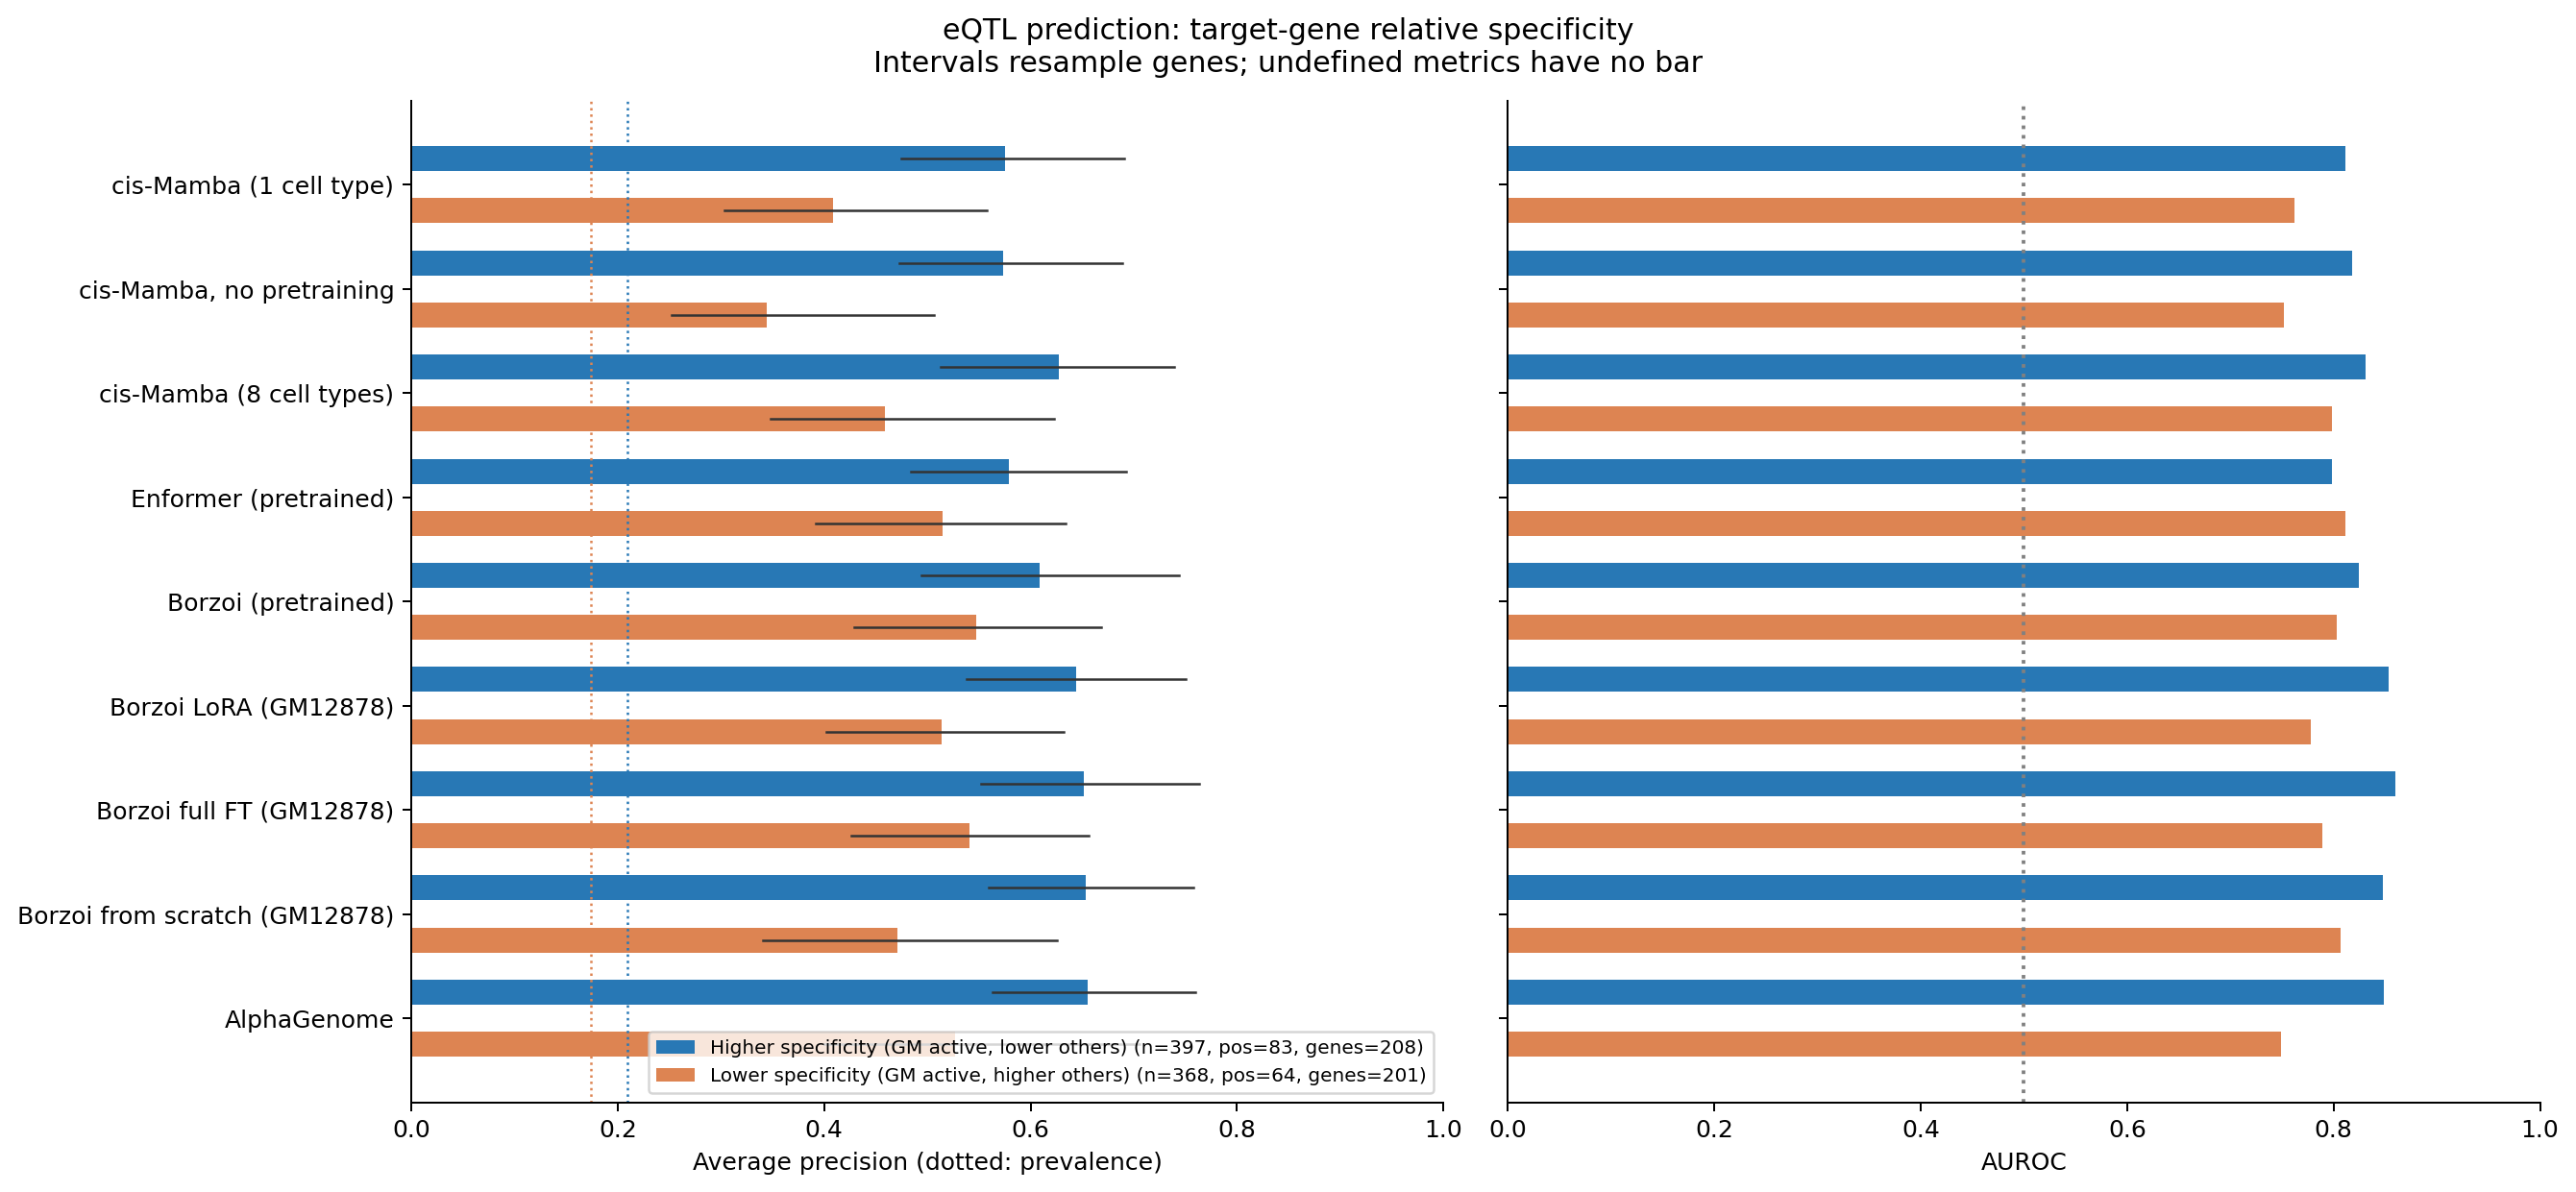

In [11]:
# Diagnostic view keeps prevalence and gene-bootstrap intervals.
fig = an.plot_diagnostic(table)
an.plt.close(fig)
display(Image(filename=str(CACHE / 'figures' / 'relative_specificity_diagnostic.png')))


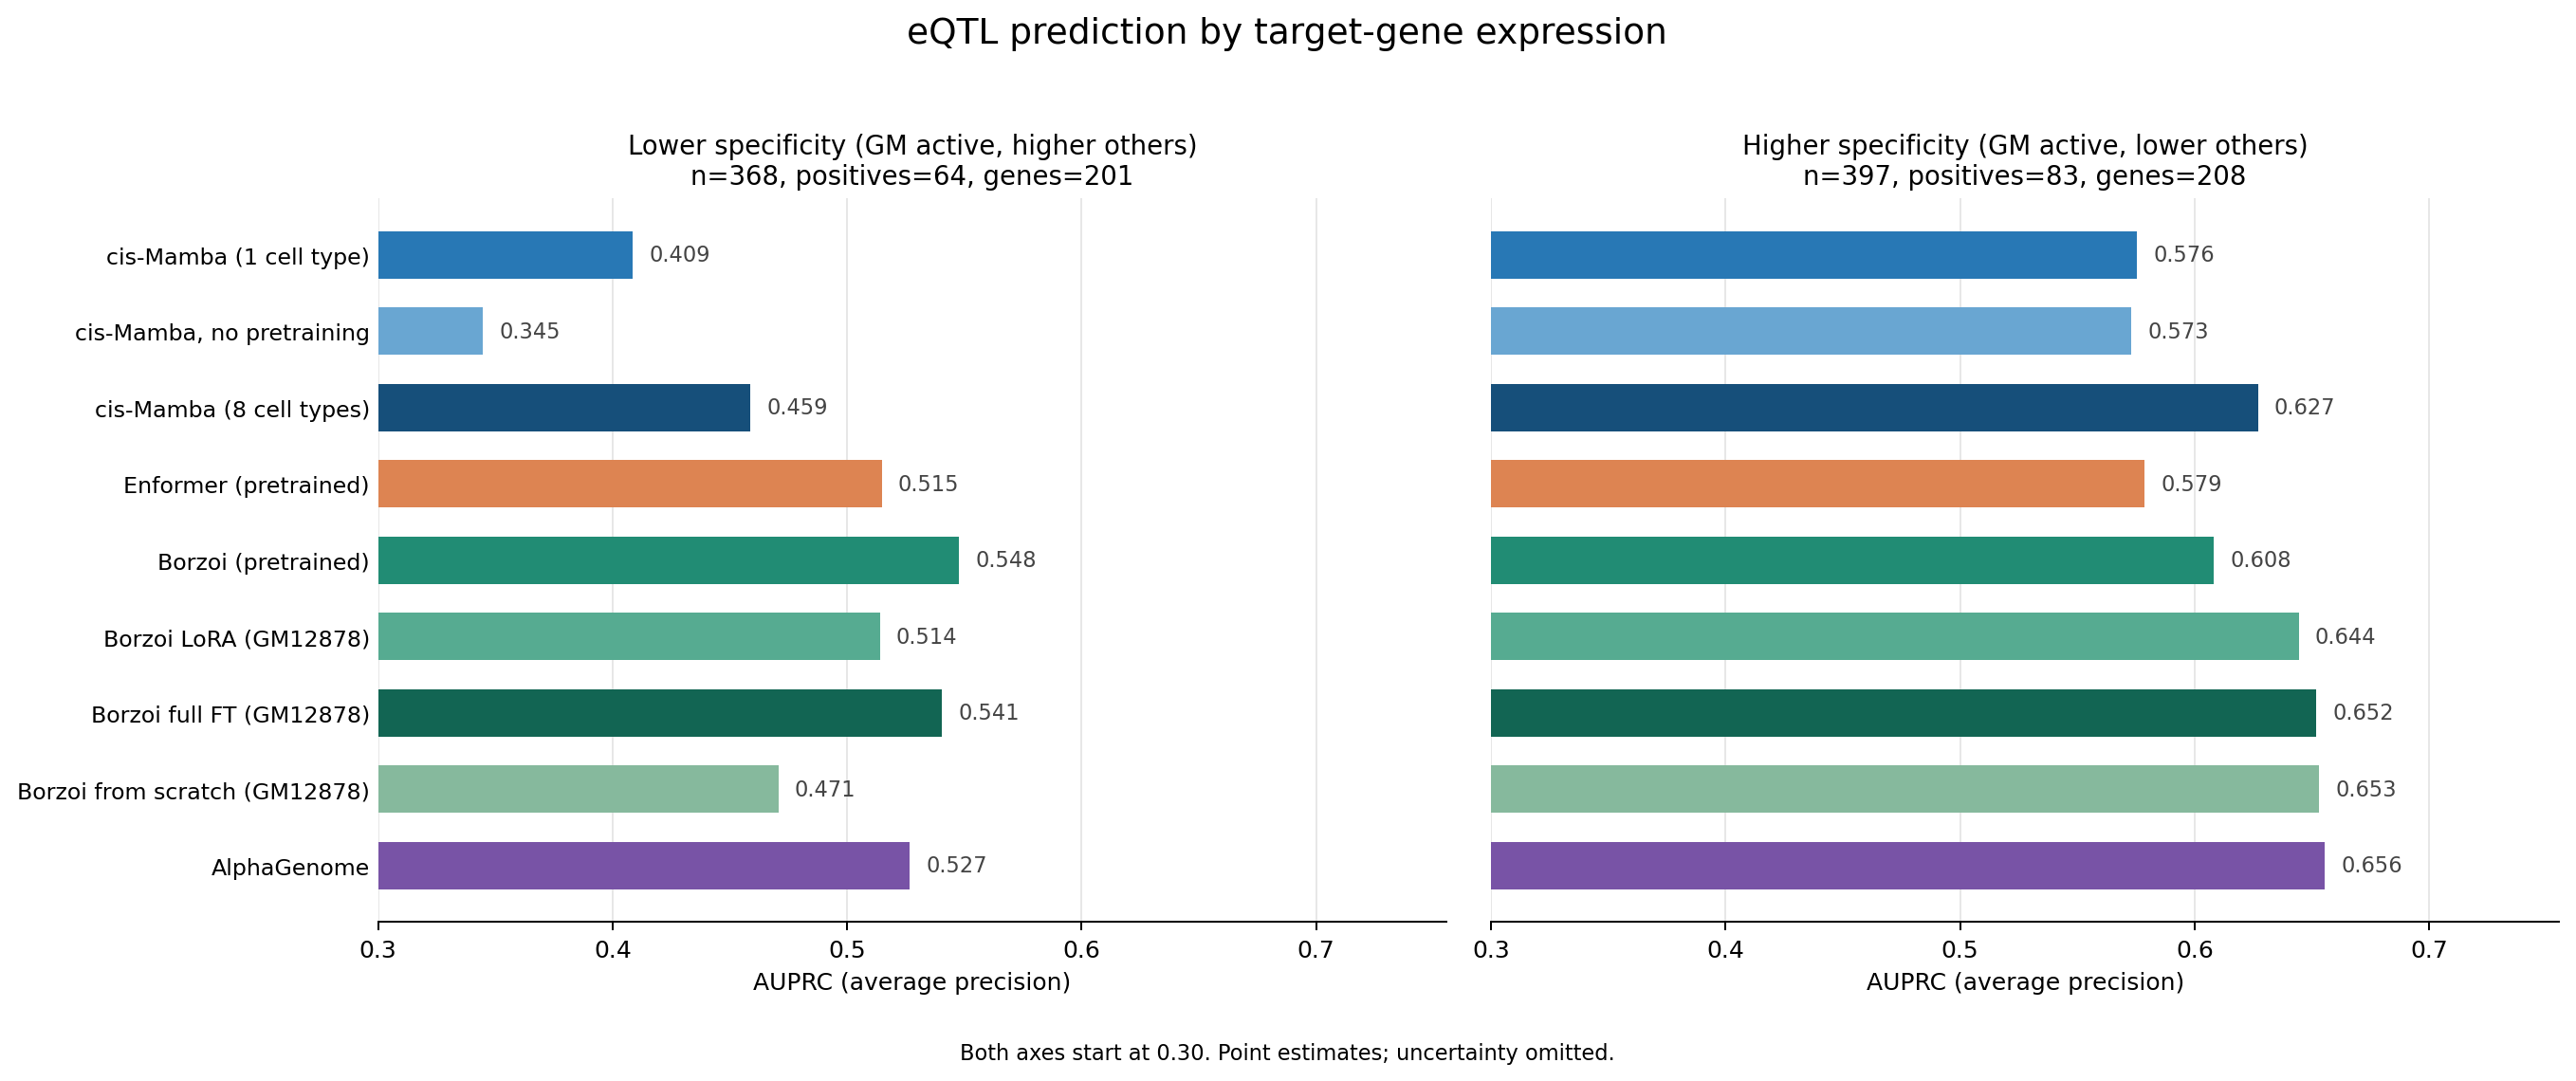

In [12]:
# Presentation: lower specificity left, higher specificity right.
# Fixed model colors, shared axes, numerical scores; no random baseline or error bars.
# A 0.30 lower limit is used only if every defined score clears it.
fig = an.plot_presentation(table, xmin=0.30)
an.plt.close(fig)
display(Image(filename=str(CACHE / 'figures' / 'relative_specificity_presentation.png')))


### Secondary extreme comparison — preserved

GM12878-active genes with others-mean below background p50 versus at/above p90. The intervening genes are excluded only from these secondary plots. Original extreme outputs before this update are archived in `legacy_extremes_before_continuous/`.


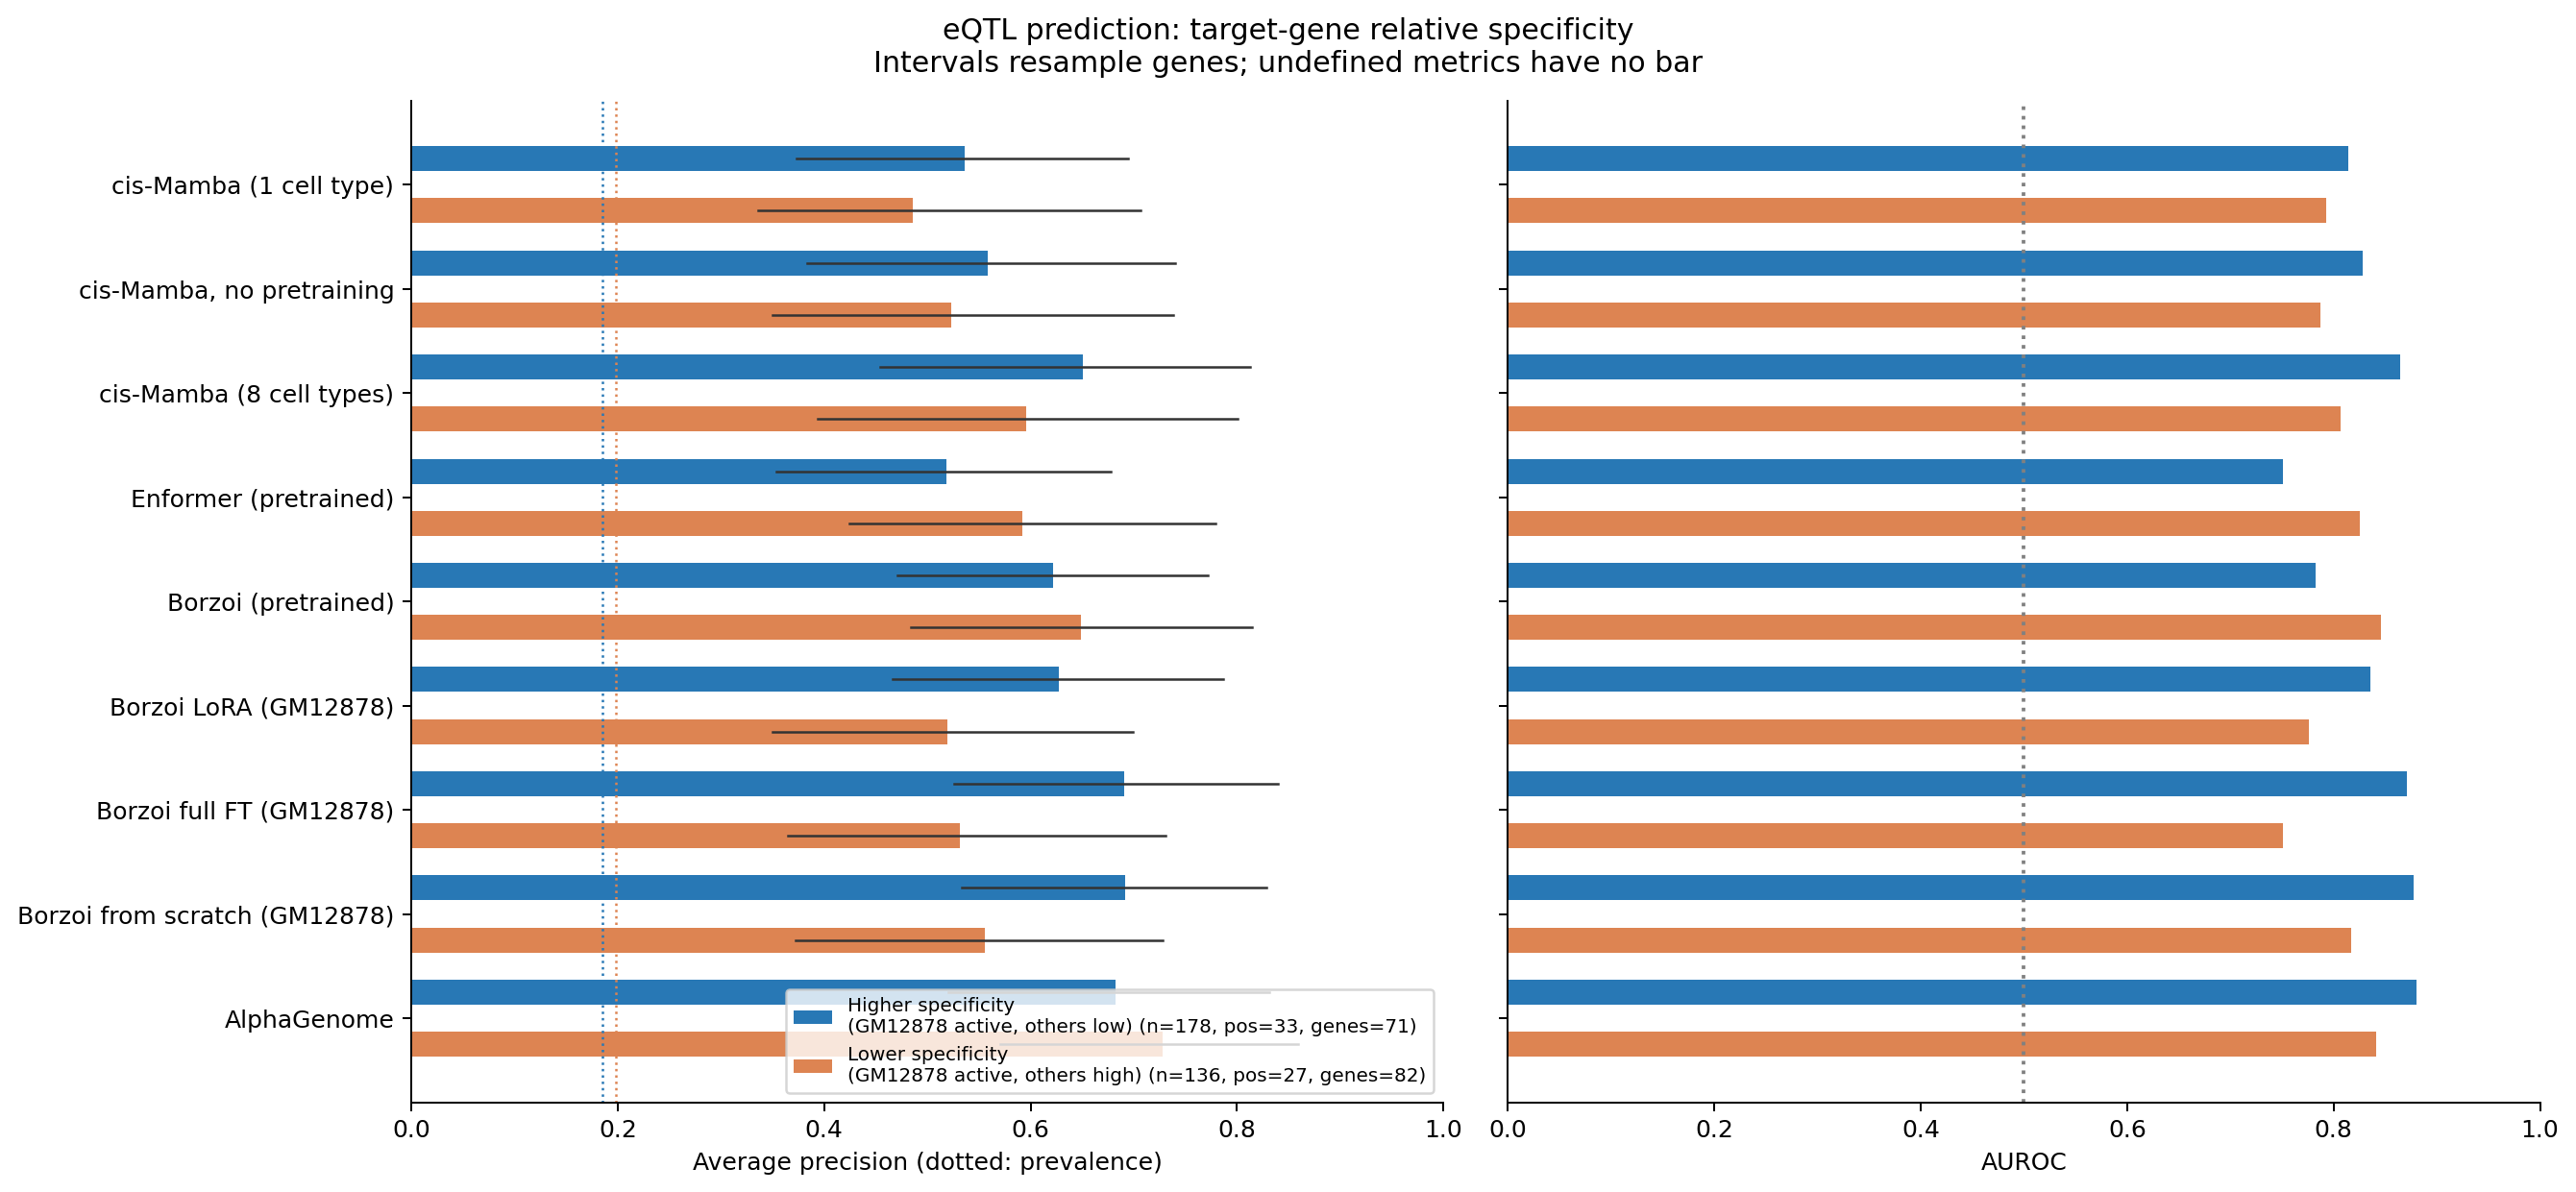

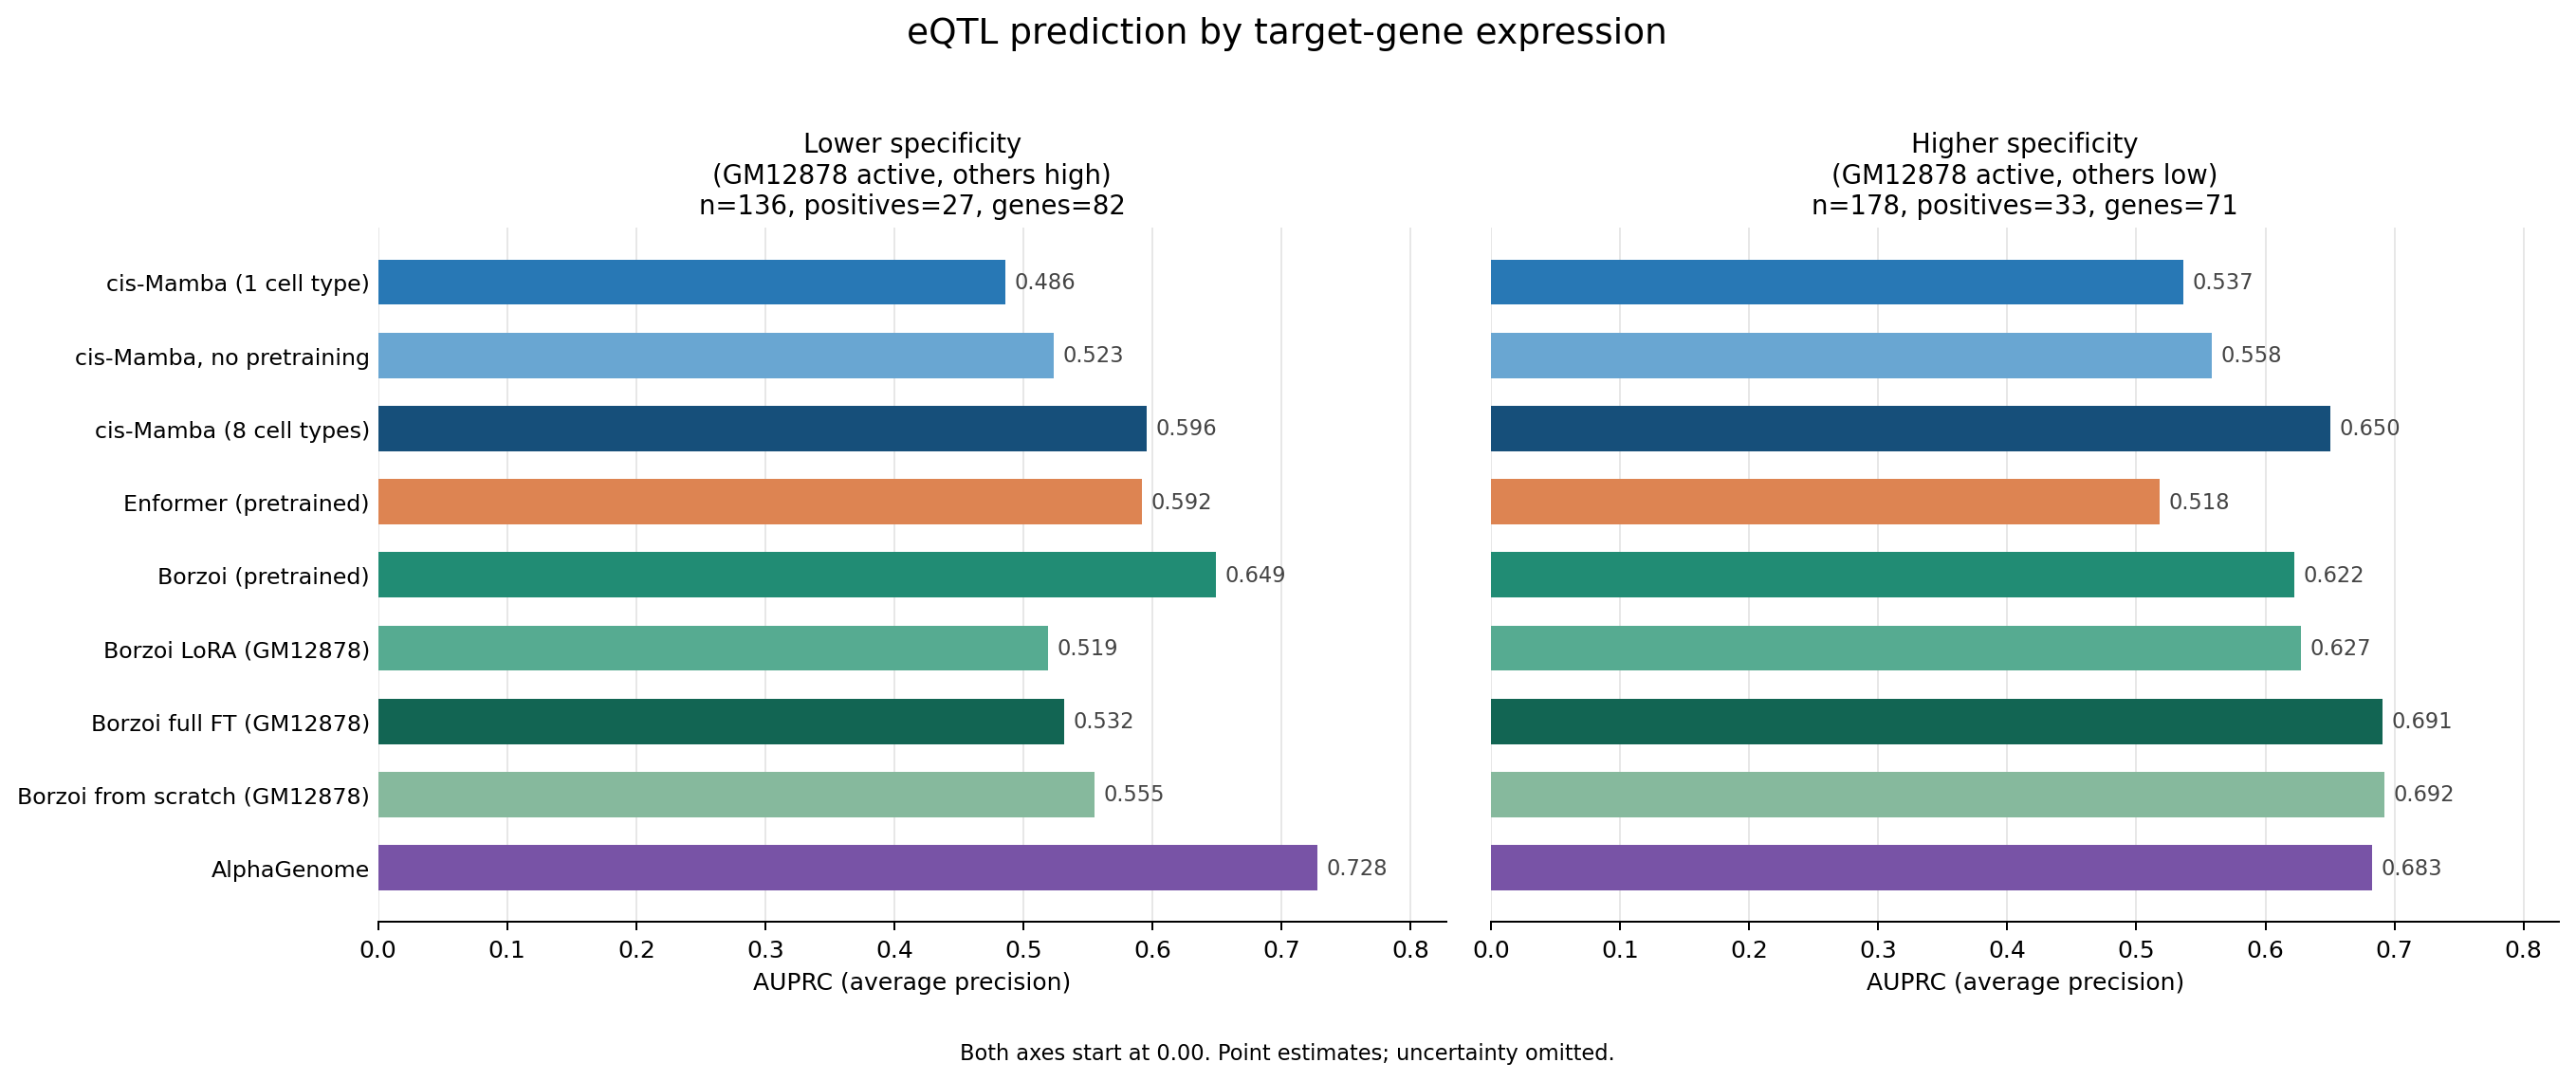

In [13]:
for plot in [an.plot_diagnostic, an.plot_presentation]:
    fig = plot(table, groups=an.EXTREME, name='extreme_specificity')
    an.plt.close(fig)
display(Image(filename=str(CACHE / 'figures' / 'extreme_specificity_diagnostic.png')))
display(Image(filename=str(CACHE / 'figures' / 'extreme_specificity_presentation.png')))


## 6. Coverage checks, exports and reruns

Promoter windows sum whole overlapping 32-bp bins; requested and actual bp extents are recorded. Overlapping spans can yield different edge bins. The optional comparison below reads source spans; ordinary reruns do not.


In [14]:
units = pd.read_csv(CACHE / 'gene_windows.tsv.gz', sep='\t')
cov = units[units.covered]
assert (cov.covered_bp >= cov.unit_bp).all()
assert (cov.covered_bp - cov.unit_bp < 2 * 32).all()
print(f'{len(cov)}/{len(units)} promoter units covered; median requested {cov.unit_bp.median():.0f} bp, summed {cov.covered_bp.median():.0f} bp.')
display(pairs.gene_mapping_status.value_counts().to_frame('benchmark pairs'))
# The gene readout sums all annotated promoters; quantify mismatch with the poster's TSS.
tss = pd.read_csv(CACHE / 'tss.tsv.gz', sep='\t')
bench = pd.read_csv(CACHE / 'benchmark_genes.tsv', sep='\t')
tss_lookup = {gene: sub.tss0.to_numpy() for gene, sub in tss.groupby('gene_id')}
nearest = [np.min(np.abs(tss_lookup[r.gene_id] - r.poster_tss))
           for r in bench.itertuples() if r.gene_id in tss_lookup]
print('Benchmark genes whose nearest annotated TSS is >1 kb from the poster TSS:', int((np.array(nearest) > 1000).sum()))


29633/30207 promoter units covered; median requested 400 bp, summed 448 bp.


,benchmark pairs
gene_mapping_status,
covered,1278
uncovered,48
absent_from_gencode,5


Benchmark genes whose nearest annotated TSS is >1 kb from the poster TSS: 13


In [15]:
RUN_SPAN_CHECK = False
if RUN_SPAN_CHECK:
    from eqtl_benchmark7_pipeline import span_table, cage_tracks, metadata, BORZOI, FOLDS, check_span_agreement
    agree = check_span_agreement(units, span_table(), cage_tracks(),
                                 {f: metadata(BORZOI / f) for f in FOLDS}, n=200)
    display(agree.relative_abs_difference.describe())
else:
    agreement = CACHE / 'span_agreement.tsv'
    print('Optional source-span check not rerun.')
    if agreement.exists():
        display(pd.read_csv(agreement, sep='\t').relative_abs_difference.describe())


Optional source-span check not rerun.


In [16]:
an.export_pairs(pairs, scores, scorable, strict)
print('Classification settings:', CACHE / 'classification_manifest.json')
print('Gene annotations:', CACHE / 'gene_expression_specificity.tsv.gz')
print('Pair scores and groups:', CACHE / 'pair_scores_and_specificity.tsv.gz')
print('Metrics and paired comparisons:', CACHE)


Classification settings: /data1/lesliec/sarthak/caduceus/code_test/eQTL_benchmark7_cache/classification_manifest.json
Gene annotations: /data1/lesliec/sarthak/caduceus/code_test/eQTL_benchmark7_cache/gene_expression_specificity.tsv.gz
Pair scores and groups: /data1/lesliec/sarthak/caduceus/code_test/eQTL_benchmark7_cache/pair_scores_and_specificity.tsv.gz
Metrics and paired comparisons: /data1/lesliec/sarthak/caduceus/code_test/eQTL_benchmark7_cache


## Rerun instructions

- Fast rerun: execute this notebook, or `python code_test/run_eqtl_benchmark7.py notebook` in the project environment.
- Validate/reuse completed extraction: `python code_test/run_eqtl_benchmark7.py cache`. Use the Slurm template for a missing cache's long scan.
- Both stages: `sbatch code_test/run_eqtl_benchmark7.slurm all`. It skips an already completed scan.
- Source prediction verification is optional: `--validate-score-sources`. Normal cached analysis reads no source coverage or prediction arrays.
- Tests: `python -m pytest code_test/test_eqtl_benchmark7.py`.
- Changing high/low thresholds, comparator inclusion or sense/combined strands uses the cache. Reference medians and secondary quantiles are recalculated for each declared sensitivity setting.
- Changing all-gene promoter windows, annotation release or extraction settings needs a new `EQTL7_CACHE`. Cached raw ±512-bp benchmark-TSS bins support local checks, not automatic recalibration of all-background thresholds. Wider raw-cache window reuse must also preserve genomic bin/overlap accounting.
- Previous strict directional outputs are archived in `legacy_directional_before_relative_split/`; previous breadth outputs have their own archive.

- Current primary display column: `specificity_group`; continuous definition and fit settings: `continuous_manifest.json`.
- Focused results: `continuous_focused_comparisons.tsv` and `focused_AP_comparisons.tsv`. They measure different quantities and should not be conflated.
- Adding independent positive loci requires a separately specified benchmark and new model predictions; this notebook does not create extra negatives or relabel existing pairs.
